In [1]:
import pandas as pd
import numpy as np

In [2]:
Ap = pd.read_csv("Admission_Predict.csv")
Ap

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65
...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67


In [3]:
Ap.columns = Ap.columns.str.strip()

Ap['Admit'] = (Ap['Chance of Admit'] > 0.87).astype(int)

Ap

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Admit
0,1,337,118,4,4.5,4.5,9.65,1.0,0.92,1
1,2,324,107,4,4.0,4.5,8.87,1.0,0.76,0
2,3,316,104,3,3.0,3.5,8.00,1.0,0.72,0
3,4,322,110,3,3.5,2.5,8.67,1.0,0.80,0
4,5,314,103,2,2.0,3.0,8.21,0.0,0.65,0
...,...,...,...,...,...,...,...,...,...,...
395,396,324,110,3,3.5,3.5,9.04,1.0,0.82,0
396,397,325,107,3,3.0,3.5,9.11,1.0,0.84,0
397,398,330,116,4,5.0,4.5,9.45,1.0,0.91,1
398,399,312,103,3,3.5,4.0,8.78,0.0,0.67,0


In [4]:
Ap = Ap.drop(columns=['Chance of Admit','Serial No.'])
Ap

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [5]:
Ap.isna().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             3
Admit                0
dtype: int64

In [11]:
Ap["Research"] = Ap["Research"].fillna(Ap["Research"].mode() [0])

In [12]:
Ap.isna().sum()

GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Admit                0
dtype: int64

In [13]:
from sklearn.model_selection import train_test_split
X = Ap.drop(columns=['Admit'])
y= Ap['Admit']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [14]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score,recall_score, f1_score

In [15]:
ap_entropy = DecisionTreeClassifier(criterion='entropy')
ap_entropy.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the cu

In [16]:
y_pred1 = ap_entropy.predict(X_train)

In [17]:
confusion_matrix(y_train,y_pred1)

array([[268,   0],
       [  0,  52]])

In [18]:
accuracy = accuracy_score(y_train,y_pred1)
precision = precision_score(y_train,y_pred1)
recall = recall_score(y_train,y_pred1)
f1 = f1_score(y_train,y_pred1)
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [19]:
y_pred = ap_entropy.predict(X_test)

In [20]:
confusion_matrix(y_test,y_pred)

array([[56,  6],
       [ 1, 17]])

In [21]:
accuracy = accuracy_score(y_test,y_pred)
precision = precision_score(y_test,y_pred)
recall = recall_score(y_test,y_pred)
f1 = f1_score(y_test,y_pred)
print(f"Accuracy: {accuracy}")
print(f"Precision: {precision}")
print(f"Recall: {recall}")
print(f"F1 Score: {f1}")

Accuracy: 0.9125
Precision: 0.7391304347826086
Recall: 0.9444444444444444
F1 Score: 0.8292682926829268


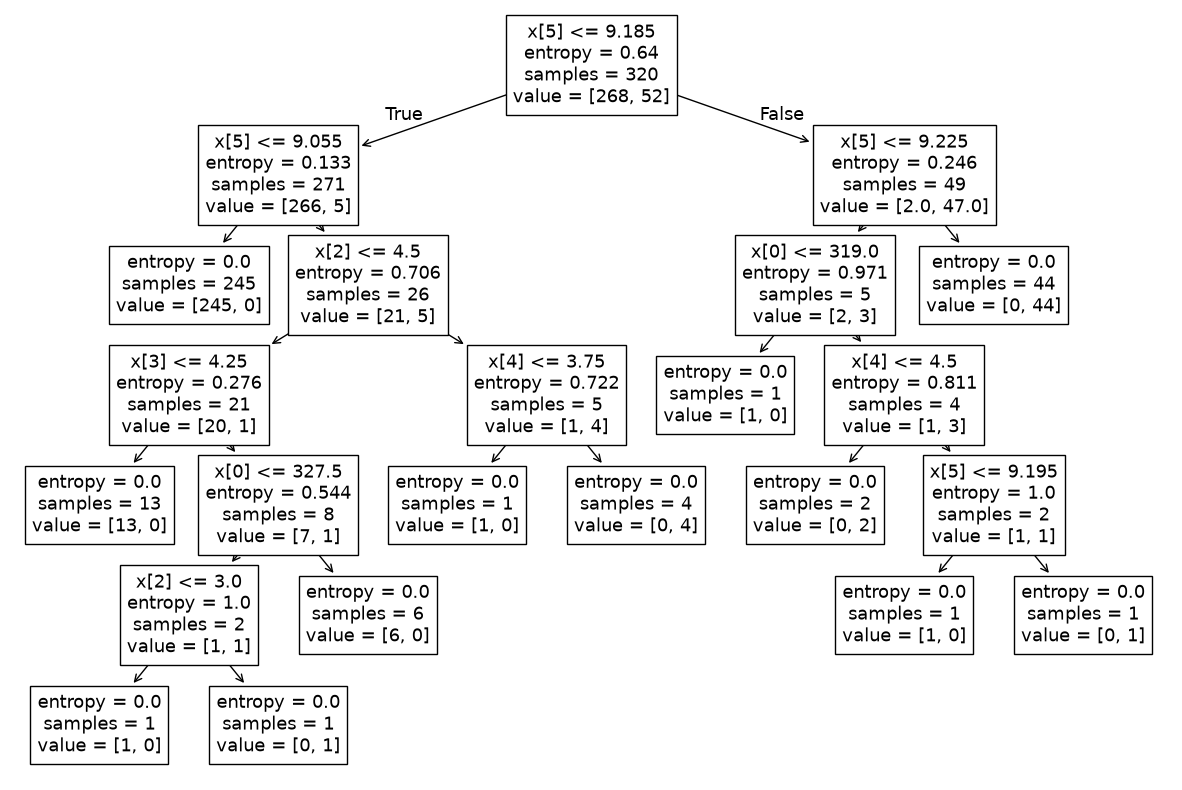

In [22]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree
plt.figure(figsize=(15,10))
plot_tree(ap_entropy)
plt.show()

In [23]:
ap_gini = DecisionTreeClassifier(criterion='gini')
ap_gini.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [24]:
y_pred1_ginni = ap_gini.predict(X_train)

In [25]:
confusion_matrix(y_train,y_pred1_ginni)

array([[268,   0],
       [  0,  52]])

In [26]:
accuracy_gini = accuracy_score(y_train,y_pred1_ginni)
precision_gini = precision_score(y_train,y_pred1_ginni)
recall_gini = recall_score(y_train,y_pred1_ginni)
f1_gini = f1_score(y_train,y_pred1_ginni)
print(f"Accuracy: {accuracy_gini}")
print(f"Precision: {precision_gini}")
print(f"Recall: {recall_gini}")
print(f"F1 Score: {f1_gini}")

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


In [27]:
y_pred_ginni = ap_gini.predict(X_test)

In [28]:
confusion_matrix(y_test,y_pred_ginni)

array([[59,  3],
       [ 1, 17]])

In [29]:
accuracy_gini = accuracy_score(y_test,y_pred_ginni)
precision_gini = precision_score(y_test,y_pred_ginni)
recall_gini = recall_score(y_test,y_pred_ginni)
f1_gini = f1_score(y_test,y_pred_ginni)
print(f"Accuracy: {accuracy_gini}")
print(f"Precision: {precision_gini}")
print(f"Recall: {recall_gini}")
print(f"F1 Score: {f1_gini}")

Accuracy: 0.95
Precision: 0.85
Recall: 0.9444444444444444
F1 Score: 0.8947368421052632


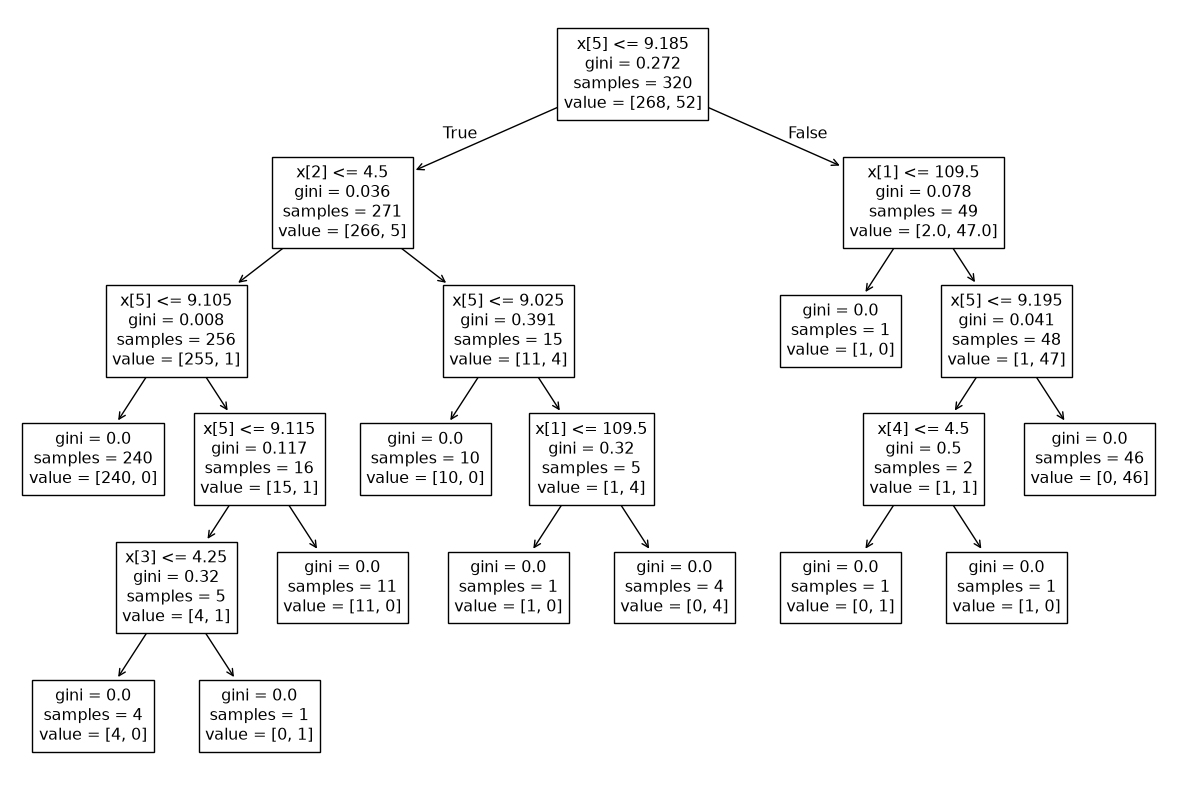

In [30]:
plt.figure(figsize=(15,10))
plot_tree(ap_gini)
plt.show()

Naive Bayes classifier

In [31]:
from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


In [32]:
y_pred_nb = nb.predict(X_train)

In [33]:
confussion_matrix_nb = confusion_matrix(y_train,y_pred_nb)
confussion_matrix_nb

array([[251,  17],
       [  2,  50]])

In [34]:
accuracy_nb = accuracy_score(y_train,y_pred_nb)
precision_nb = precision_score(y_train,y_pred_nb)
recall_nb = recall_score(y_train,y_pred_nb)
f1_nb = f1_score(y_train,y_pred_nb)
print(f"Accuracy: {accuracy_nb}")
print(f"Precision: {precision_nb}")
print(f"Recall: {recall_nb}")
print(f"F1 Score: {f1_nb}")

Accuracy: 0.940625
Precision: 0.746268656716418
Recall: 0.9615384615384616
F1 Score: 0.8403361344537815


In [35]:
y_pred1_nb = nb.predict(X_test)

In [36]:
confussion_matrix_nb = confusion_matrix(y_test,y_pred1_nb)
confussion_matrix_nb

array([[57,  5],
       [ 1, 17]])

In [37]:
accuracy_nb = accuracy_score(y_test,y_pred1_nb)
precision_nb = precision_score(y_test,y_pred1_nb)
recall_nb = recall_score(y_test,y_pred1_nb)
f1_nb = f1_score(y_test,y_pred1_nb)
print(f"Accuracy: {accuracy_nb}")
print(f"Precision: {precision_nb}")
print(f"Recall: {recall_nb}")
print(f"F1 Score: {f1_nb}")

Accuracy: 0.925
Precision: 0.7727272727272727
Recall: 0.9444444444444444
F1 Score: 0.85


In [38]:
X_train

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
3,322,110,3,3.5,2.5,8.67,1.0
18,318,110,3,4.0,3.0,8.80,0.0
202,340,120,5,4.5,4.5,9.91,1.0
250,320,104,3,3.0,2.5,8.57,1.0
274,315,100,1,2.0,2.5,7.95,0.0
...,...,...,...,...,...,...,...
71,336,112,5,5.0,5.0,9.76,1.0
106,329,111,4,4.5,4.5,9.18,1.0
270,306,105,2,2.5,3.0,8.22,1.0
348,302,99,1,2.0,2.0,7.25,0.0


In [39]:
x = X_train[['GRE Score','TOEFL Score']]

In [40]:
nb1 = GaussianNB()
nb1.fit(x,y_train)
y_pred_new= nb1.predict(x)

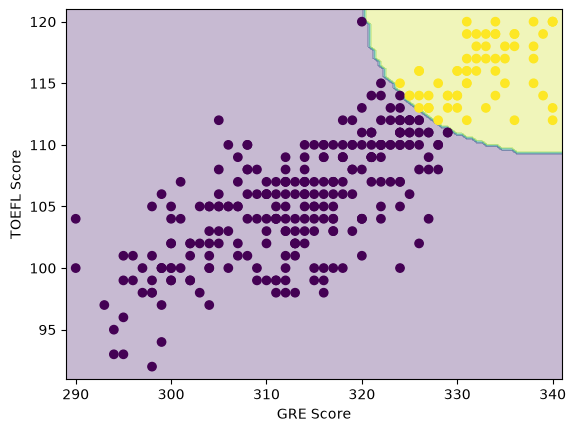

In [41]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt

DecisionBoundaryDisplay.from_estimator(nb1,x,response_method='predict',alpha=0.3)
plt.scatter(x['GRE Score'] ,x['TOEFL Score'],c =y_pred_new )

User Input

In [42]:
Ap

,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Admit
0,337,118,4,4.5,4.5,9.65,1.0,1
1,324,107,4,4.0,4.5,8.87,1.0,0
2,316,104,3,3.0,3.5,8.00,1.0,0
3,322,110,3,3.5,2.5,8.67,1.0,0
4,314,103,2,2.0,3.0,8.21,0.0,0
...,...,...,...,...,...,...,...,...
395,324,110,3,3.5,3.5,9.04,1.0,0
396,325,107,3,3.0,3.5,9.11,1.0,0
397,330,116,4,5.0,4.5,9.45,1.0,1
398,312,103,3,3.5,4.0,8.78,0.0,0


In [44]:

gre = float(input("GRE Score (290-340): "))
toefl = float(input("TOEFL Score (90-120): "))
rating = float(input("University Rating (1-5): "))
sop = float(input("SOP Strength (1-5): "))
lor = float(input("LOR Strength (1-5): "))
cgpa = float(input("CGPA (1-10): "))
research = float(input("Research Experience (1 for Yes, 0 for No): "))

new_data = pd.DataFrame([{
    "GRE Score": gre,
    "TOEFL Score": toefl,
    "University Rating": rating,
    "SOP": sop,
    "LOR": lor,
    "CGPA": cgpa,
    "Research": research
}])

new_data = new_data[X.columns]


GRE Score (290-340):  310
TOEFL Score (90-120):  115
University Rating (1-5):  5
SOP Strength (1-5):  4
LOR Strength (1-5):  5
CGPA (1-10):  9.4
Research Experience (1 for Yes, 0 for No):  1


Prediction Through Entropy Model

In [45]:
prediction = ap_entropy.predict(new_data)
if prediction == 0:
  print('You are not eligible for admission')
else:
  print('You are eligible for admission')

You are eligible for admission


Prediction Through Ginny Index Model

In [46]:
prediction = ap_gini.predict(new_data)
if prediction == 0:
  print('You are not eligible for admission')
else:
  print('You are eligible for admission')

You are eligible for admission


Prediction Through Naive Bayes classifier model

In [47]:
prediction = nb.predict(new_data)
if prediction == 0:
  print('You are not eligible for admission')
else:
  print('You are eligible for admission')

You are eligible for admission


In [47]:
# Classification is a supervised machine learning technique used to predict categorical output or class labels.
# A Decision Tree is a supervised machine learning algorithm that makes decisions using a tree-like structure.
# - It consists of Root Node, Decision Nodes and Leaf Nodes.
# - It splits data based on conditions.
# - It is used for classification and regression.

# Entropy: Measures the impurity or randomness in the dataset.
# Information Gain: Measures how much entropy decreases after splitting the data.
# Gini Index measures the impurity of a dataset.
# - Lower Gini means purer data.
# - Higher Gini means more mixed classes.

# Naïve Bayes : It predicts the class based on probabilities and assumes that all features are independent of each other.
# Gaussian Naïve Bayes is a type of Naïve Bayes classifier used for continuous numerical data. It assumes that the features follow a normal (Gaussian) distribution.

You are eligible for admission
